In [ ]:
%pip install ipywidgets

In [11]:
import os
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm  # Changed this line
from pathlib import Path

In [12]:
# 1. Define your input and output directories here
INPUT_MASK_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks"
OUTPUT_MASK_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/healthy-masks"

# 2. Create the output directory if it doesn't exist
os.makedirs(OUTPUT_MASK_DIR, exist_ok=True)

# 3. Gather all image files (handling both png and jpg formats)
valid_extensions = ('.png', '.jpg', '.jpeg')
mask_files = [f for f in os.listdir(INPUT_MASK_DIR) if f.lower().endswith(valid_extensions)]

print(f"Found {len(mask_files)} masks to process.")

# 4. Process and invert each mask
for filename in tqdm(mask_files, desc="Generating Healthy Masks"):
    input_path = os.path.join(INPUT_MASK_DIR, filename)
    output_path = os.path.join(OUTPUT_MASK_DIR, filename)
    
    # Read the mask in grayscale
    polyp_mask = cv2.imread(input_path, cv2.IMREAD_GRAYSCALE)
    
    if polyp_mask is None:
        print(f"Warning: Could not read {filename}. Skipping.")
        continue
        
    # Invert the mask: Polyp (255) becomes 0, Background (0) becomes 255
    healthy_mask = cv2.bitwise_not(polyp_mask)
    
    # Save the inverted mask to the new directory
    cv2.imwrite(output_path, healthy_mask)

print("Processing complete!")

Found 1000 masks to process.




Generating Healthy Masks:   0%|                                                                                                       | 0/1000 [00:00<?, ?it/s]

Generating Healthy Masks:   0%|▏                                                                                              | 2/1000 [00:00<00:52, 19.05it/s]

Generating Healthy Masks:   1%|▊                                                                                              | 8/1000 [00:00<00:25, 38.97it/s]

Generating Healthy Masks:   1%|█▏                                                                                            | 13/1000 [00:00<00:22, 43.70it/s]

Generating Healthy Masks:   2%|█▉                                                                                            | 20/1000 [00:00<00:18, 51.70it/s]

Generating Healthy Masks:   3%|██▌                                                                                           | 27/1000 [00:00<00:17, 56.16it/s]

Generating Healthy Masks:   4%|█

Processing complete!


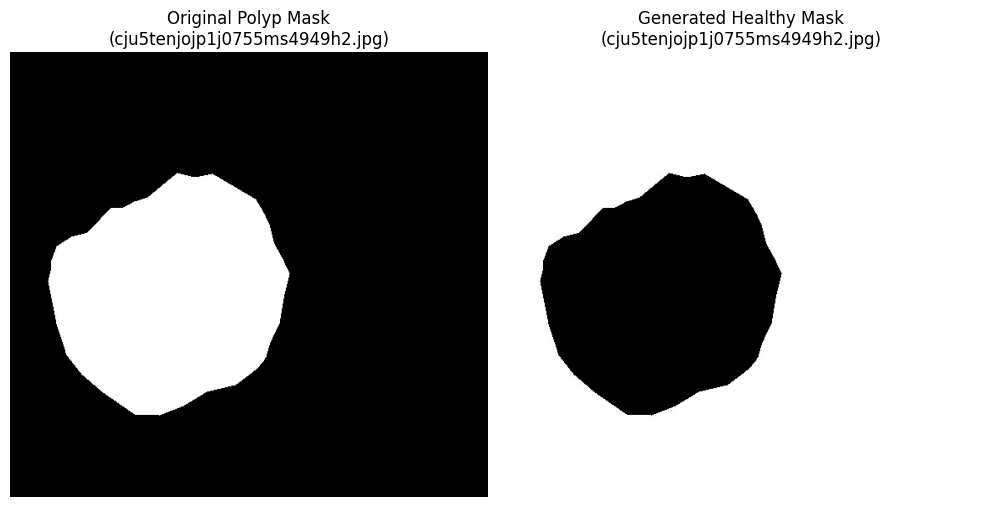

In [13]:
import random

# Select a random image from the generated outputs
sample_file = random.choice(mask_files)
orig_path = os.path.join(INPUT_MASK_DIR, sample_file)
new_path = os.path.join(OUTPUT_MASK_DIR, sample_file)

orig_mask = cv2.imread(orig_path, cv2.IMREAD_GRAYSCALE)
new_mask = cv2.imread(new_path, cv2.IMREAD_GRAYSCALE)

# Plotting the comparison
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(orig_mask, cmap='gray')
axes[0].set_title(f"Original Polyp Mask\n({sample_file})")
axes[0].axis('off')

axes[1].imshow(new_mask, cmap='gray')
axes[1].set_title(f"Generated Healthy Mask\n({sample_file})")
axes[1].axis('off')

plt.tight_layout()
plt.show()